## ResNet Hypertuning

Optimize *learning rate* and *regularization parameter* of the `ResNet50` (22 species) on the whole downloaded dataset, using the `Hyperband` algorithm from `keras_tuner`.

In [ ]:
import sys
sys.path.append('./wingbeats/')

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import keras_tuner as kt
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building hyper simple classifiers

In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.4.1
/device:GPU:0
Num GPUs available: 1


In [4]:
use_mini_dataset   = False # use whole dataset
compress_B_lucorum = True  # the 4 similar species are compressed together
bees_subfolder = '22_species/' if compress_B_lucorum else '25_species/'

dataset_folder = 'Bees_Christian/' if use_mini_dataset else 'Bees/'
metafolder = './beexplainable/metafiles/'

BEES_PATH = '../data/data_lstudio/' + dataset_folder
IMAGES_PATH = metafolder + dataset_folder + 'images.txt'
IMAGES_LABELS_PATH = metafolder + dataset_folder + bees_subfolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + dataset_folder + bees_subfolder + 'classes.txt'

MODELS_PATH  = './beexplainable/models/'

## Load images

In [5]:
batch_size = 16 if use_mini_dataset else 64
img_height = img_width = 224
crop_to_bbox = False # whether to crop image to bbox
overlay_mask = False # whether to segment object and hide background

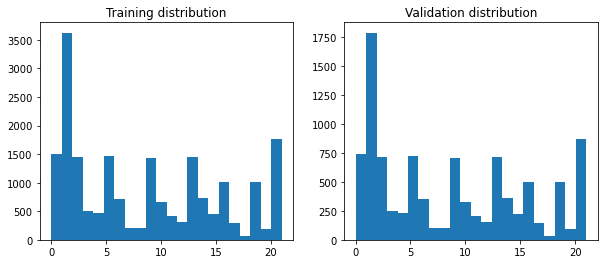

In [6]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

# Split into training and validation
train_files, val_files, y_train, y_val = train_test_split(file_ids, y_true, test_size = 0.33, random_state = 2022,
                                                          shuffle = True, stratify = y_true)

plt.figure(figsize = (10, 4))
plt.subplot(121)
plt.hist(y_train, bins = len(np.unique(y_train)))
plt.title('Training distribution')

plt.subplot(122)
plt.hist(y_val, bins = len(np.unique(y_val)))
plt.title('Validation distribution')
plt.show()

In [7]:
# Add extension to path if extra input transformation is enabled
input_form = 'raw'
if crop_to_bbox and not overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_bbox/'
    input_form = 'bbox'
elif not crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked/Whole/'
    input_form = 'mask'
elif crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked_bbox/'
    input_form = 'mask_bbox'
print(BEES_PATH)

../data/data_lstudio/Bees/


In [8]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, BEES_PATH),
                                          label)

In [9]:
# Conversion to tf.Dataset
train_set = ps.parse_to_dataset(train_files, y_train, parse_image_lab)
train_set = train_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

val_set = ps.parse_to_dataset(val_files, y_val, parse_image_lab)
val_set = val_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
train_set = train_set.map(lambda x, y: (normalization_layer(x), y))
val_set   = val_set.map(lambda x, y: (normalization_layer(x), y))

In [10]:
# Augmentation: flips, rotation, contrast and brightness
augment = True
if augment:
    aug_train_flip_1 = train_set.map(lambda x, y: (tf.image.flip_left_right(x), y))
    aug_train_flip_2 = train_set.map(lambda x, y: (tf.image.flip_up_down(x), y))
    aug_train_rot = train_set.map(lambda x, y: (tf.image.rot90(x), y))
    aug_train_cont = train_set.map(lambda x, y: (tf.image.random_contrast(x, 0.2, 0.5), y))
    aug_train_brt = train_set.map(lambda x, y: (tf.image.random_brightness(x, 0.5), y))

    train_set = train_set.concatenate(aug_train_flip_1).concatenate(aug_train_flip_2).concatenate(aug_train_rot)
    train_set = train_set.concatenate(aug_train_cont).concatenate(aug_train_brt)

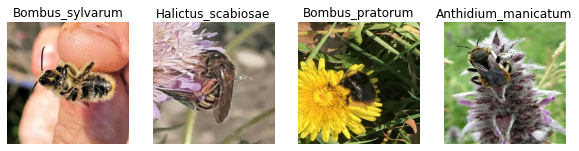

In [11]:
# Plot a few examples
plt.figure(figsize = (10, 10))
num_cols = min(4, batch_size)
with tf.device('/CPU:0'):
    for images, labels in train_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

In [12]:
for image_batch, labels_batch in train_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(12, shape=(), dtype=uint8)


## Hypertuning

In [13]:
# Define initial training parameters
epochs = 30 # should be large enough for EarlyStopping to be beneficial
drop_rate = 0.5
in_shape = (img_width, img_height, 3)

# Hyperparameter values
lr_values = reg_values = [1e-2, 1e-3, 1e-4]

# Hyperband parameters
hyper_factor = 2 # 1/factor configurations survive every bracket
hyper_it = 3

In [14]:
# Other model parameters
out_shape = len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
dataset_type = 'all' # model was trained on whole dataset and is now tested on mini dataset
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_raw' # model was trained on raw whole dataset

# Logs directory for TensorBoard
hypertune_dir = MODELS_PATH + dataset_type + '/' + bees_subfolder + model_name + '/hypertuning/'

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

In [15]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

# Callbacks
earlyStopper = EarlyStopping(monitor = 'val_loss', min_delta = 1e-1, patience = 3, verbose = 1)
model_callbacks = [earlyStopper]

In [16]:
# Construct specific factory funtion for hypertunable model
build_hypermodel = lambda hp: wm.build_hyper_simple_classifier(hp, in_shape, out_shape, cnn, lr_values, reg_values,
                                                               loss, metrics, input_name = "jpg", model_name = model_name)

In [17]:
# Instantiate tuner
tuner = kt.Hyperband(build_hypermodel,
                     objective = 'val_loss',
                     max_epochs = epochs,
                     factor = hyper_factor,
                     hyperband_iterations = hyper_it,
                     directory = hypertune_dir,
                     project_name = model_name,
                     overwrite = True)

In [18]:
# Run hypertuning
tuner.search(train_set, epochs = epochs, validation_data = val_set, callbacks = [earlyStopper])

# Get the optimal hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

Trial 9 Complete [00h 18m 16s]
val_loss: 1.6625062227249146

Best val_loss So Far: 1.6625062227249146
Total elapsed time: 02h 46m 38s
INFO:tensorflow:Oracle triggered exit


In [19]:
# Save best HPs
print('LR = ' + str(best_hps.get('learning_rate')) + ', Reg = ' + str(best_hps.get('reg_param')))
with open(hypertune_dir + 'best_hyperparams.txt', 'a') as f:
    f.write('LR = ' + str(best_hps.get('learning_rate')) + ', Reg = ' + str(best_hps.get('reg_param')))
f.close()

LR = 0.0001, Reg = 0.0001
